In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Libraries imported successfully!")


Libraries imported successfully!


In [2]:
DATA_PATH = Path("../data/interim/retail_demand_clean.csv")

df = pd.read_csv(DATA_PATH, parse_dates=["date"])

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '..\\data\\interim\\retail_demand_clean.csv'

In [3]:
from pathlib import Path

print("Current notebook working folder:")
print(Path.cwd())

print("\nFiles in the current folder:")
print(list(Path.cwd().iterdir()))

Current notebook working folder:
C:\Users\Gnana prakash\Desktop\Demand-Forecasting-Inventory-Optimization

Files in the current folder:
[WindowsPath('C:/Users/Gnana prakash/Desktop/Demand-Forecasting-Inventory-Optimization/.gitignore'), WindowsPath('C:/Users/Gnana prakash/Desktop/Demand-Forecasting-Inventory-Optimization/.ipynb_checkpoints'), WindowsPath('C:/Users/Gnana prakash/Desktop/Demand-Forecasting-Inventory-Optimization/.pytest_cache'), WindowsPath('C:/Users/Gnana prakash/Desktop/Demand-Forecasting-Inventory-Optimization/.venv'), WindowsPath('C:/Users/Gnana prakash/Desktop/Demand-Forecasting-Inventory-Optimization/01_data_exploration.ipyn.ipynb'), WindowsPath('C:/Users/Gnana prakash/Desktop/Demand-Forecasting-Inventory-Optimization/data'), WindowsPath('C:/Users/Gnana prakash/Desktop/Demand-Forecasting-Inventory-Optimization/notebooks'), WindowsPath('C:/Users/Gnana prakash/Desktop/Demand-Forecasting-Inventory-Optimization/README.md'), WindowsPath('C:/Users/Gnana prakash/Desktop/D

In [5]:
from pathlib import Path

project_folder = Path.cwd()

for file in project_folder.rglob("retail_demand_clean.csv"):
    print("Dataset found:", file.resolve())

Dataset found: C:\Users\Gnana prakash\Desktop\Demand-Forecasting-Inventory-Optimization\data\interim\retail_demand_clean.csv


In [4]:
df = pd.read_csv(
    r"C:\Users\Gnana prakash\Desktop\Demand-Forecasting-Inventory-Optimization\data\interim\retail_demand_clean.csv",
    parse_dates=["date"]
)

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Rows and columns: (540, 3)


,date,product_id,units_sold
0,2025-01-01,P001,52
1,2025-01-02,P001,44
2,2025-01-03,P001,55
3,2025-01-04,P001,66
4,2025-01-05,P001,48


In [6]:

print("1. Dataset information:")
df.info()

print("\n2. Missing values:")
display(df.isnull().sum())

print("\n3. Duplicate rows:")
print(df.duplicated().sum())

print("\n4. Summary statistics:")
display(df.describe())

print("\n5. Number of products:")
print(df["product_id"].nunique())

print("\n6. Date range:")
print("Start date:", df["date"].min())
print("End date:", df["date"].max())


1. Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 540 entries, 0 to 539
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        540 non-null    datetime64[us]
 1   product_id  540 non-null    str           
 2   units_sold  540 non-null    int64         
dtypes: datetime64[us](1), int64(1), str(1)
memory usage: 14.9 KB

2. Missing values:


date          0
product_id    0
units_sold    0
dtype: int64


3. Duplicate rows:
0

4. Summary statistics:


,date,units_sold
count,540,540.000000
mean,2025-03-31 12:00:00,57.301852
min,2025-01-01 00:00:00,26.000000
25%,2025-02-14 18:00:00,43.000000
50%,2025-03-31 12:00:00,54.000000
75%,2025-05-15 06:00:00,71.000000
max,2025-06-29 00:00:00,103.000000
std,NaN,17.774604



5. Number of products:
3

6. Date range:
Start date: 2025-01-01 00:00:00
End date: 2025-06-29 00:00:00


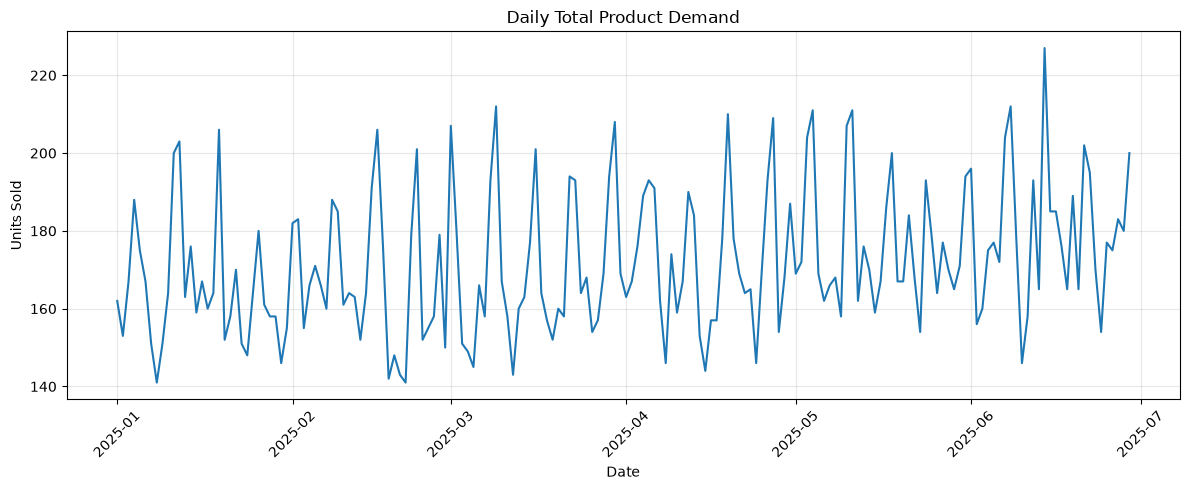

In [7]:

daily_demand = df.groupby("date")["units_sold"].sum()

plt.figure(figsize=(12, 5))
plt.plot(daily_demand.index, daily_demand.values)
plt.title("Daily Total Product Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


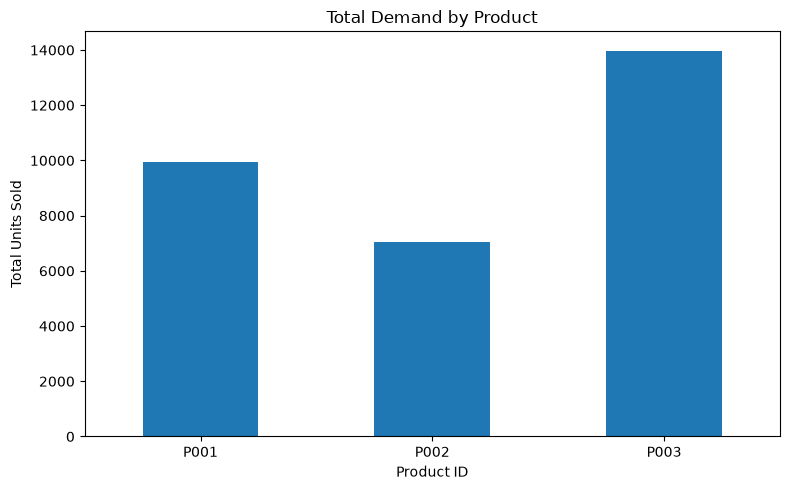

Total demand for each product:


product_id
P001     9933
P002     7032
P003    13978
Name: units_sold, dtype: int64

In [8]:

product_demand = df.groupby("product_id")["units_sold"].sum()

plt.figure(figsize=(8, 5))
product_demand.plot(kind="bar")
plt.title("Total Demand by Product")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Total demand for each product:")
display(product_demand)


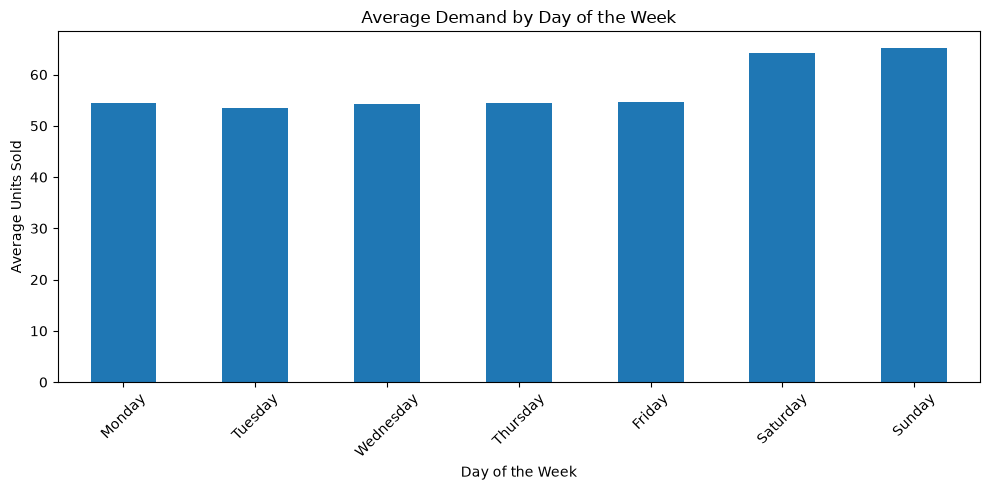

day_of_week
Monday       54.546667
Tuesday      53.400000
Wednesday    54.346154
Thursday     54.512821
Friday       54.717949
Saturday     64.153846
Sunday       65.179487
Name: units_sold, dtype: float64

In [9]:

df["day_of_week"] = df["date"].dt.day_name()

weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand = (
    df.groupby("day_of_week")["units_sold"]
    .mean()
    .reindex(weekday_order)
)

plt.figure(figsize=(10, 5))
weekday_demand.plot(kind="bar")
plt.title("Average Demand by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(weekday_demand)


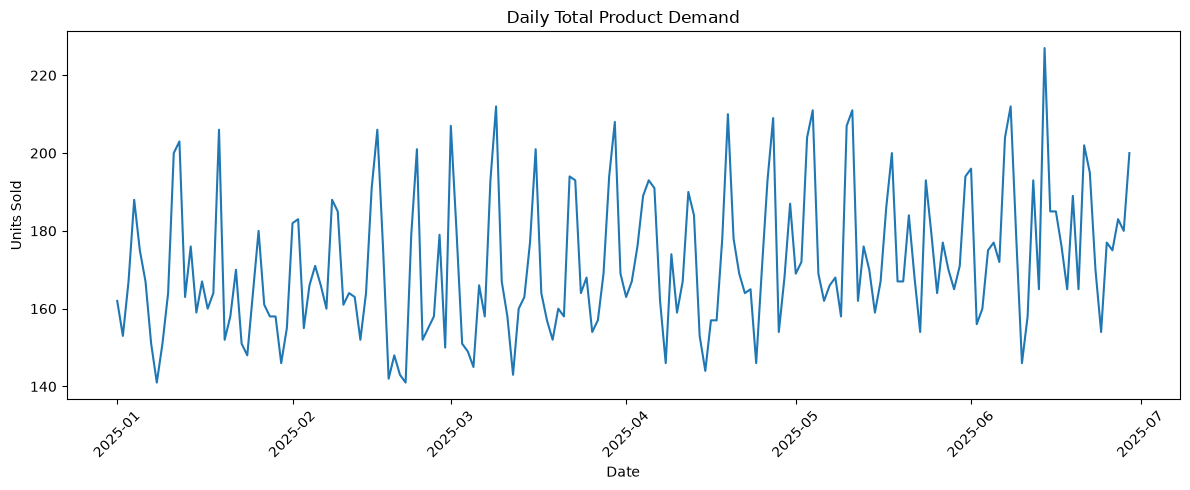

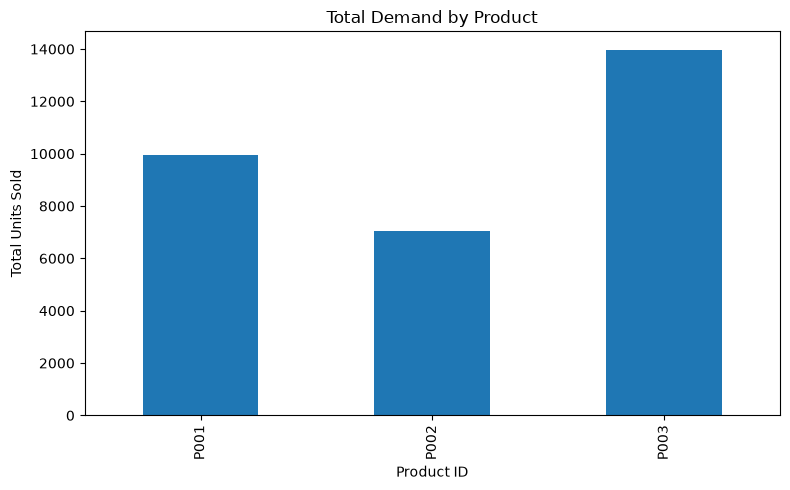

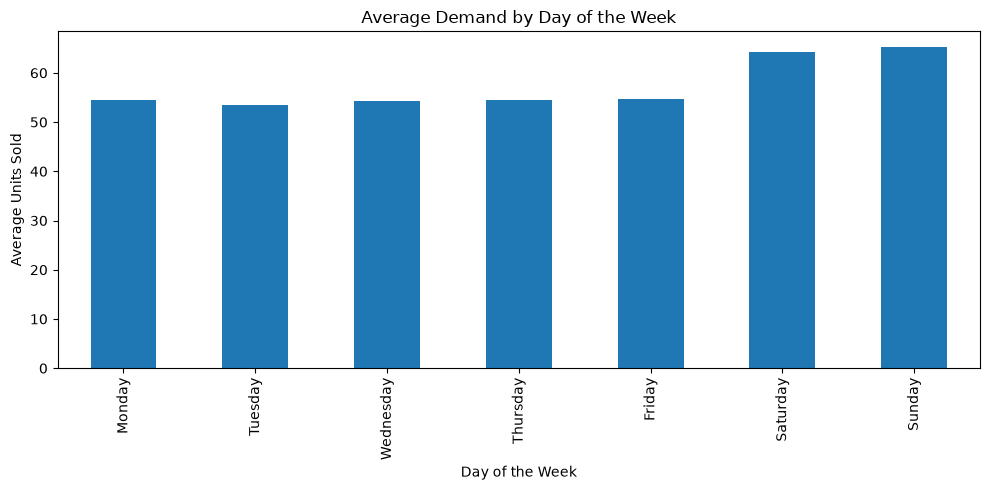

All three charts saved successfully!
Saved in: C:\Users\Gnana prakash\Desktop\reports\figures


In [10]:

from pathlib import Path

FIGURES_DIR = Path("../reports/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Save daily total demand
daily_demand = df.groupby("date")["units_sold"].sum()
plt.figure(figsize=(12, 5))
plt.plot(daily_demand.index, daily_demand.values)
plt.title("Daily Total Product Demand")
plt.xlabel("Date")
plt.ylabel("Units Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "daily_demand.png", dpi=150)
plt.show()
plt.close()

# Save total demand by product
product_demand = df.groupby("product_id")["units_sold"].sum()
plt.figure(figsize=(8, 5))
product_demand.plot(kind="bar")
plt.title("Total Demand by Product")
plt.xlabel("Product ID")
plt.ylabel("Total Units Sold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "product_demand.png", dpi=150)
plt.show()
plt.close()

# Save average demand by weekday
plt.figure(figsize=(10, 5))
weekday_demand.plot(kind="bar")
plt.title("Average Demand by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Units Sold")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "weekday_demand.png", dpi=150)
plt.show()
plt.close()

print("All three charts saved successfully!")
print("Saved in:", FIGURES_DIR.resolve())


In [11]:

from pathlib import Path

quality_report = pd.DataFrame({
    "check": [
        "Total rows",
        "Total columns",
        "Missing values",
        "Duplicate rows",
        "Duplicate product-date records",
        "Negative demand values",
        "Number of products",
        "Start date",
        "End date"
    ],
    "result": [
        len(df),
        len(df.columns),
        int(df.isnull().sum().sum()),
        int(df.duplicated().sum()),
        int(df.duplicated(subset=["date", "product_id"]).sum()),
        int((df["units_sold"] < 0).sum()),
        int(df["product_id"].nunique()),
        str(df["date"].min().date()),
        str(df["date"].max().date())
    ]
})

REPORT_DIR = Path("../reports")
REPORT_DIR.mkdir(parents=True, exist_ok=True)

quality_report.to_csv(
    REPORT_DIR / "data_quality_report.csv",
    index=False
)

display(quality_report)
print("Data quality report saved successfully!")


,check,result
0,Total rows,540
1,Total columns,4
2,Missing values,0
3,Duplicate rows,0
4,Duplicate product-date records,0
5,Negative demand values,0
6,Number of products,3
7,Start date,2025-01-01
8,End date,2025-06-29


Data quality report saved successfully!


In [12]:

data_dictionary = pd.DataFrame({
    "column_name": ["date", "product_id", "units_sold"],
    "data_type": [
        str(df["date"].dtype),
        str(df["product_id"].dtype),
        str(df["units_sold"].dtype)
    ],
    "description": [
        "Date of product sales",
        "Unique identifier for each product",
        "Number of units sold on that date"
    ],
    "data_source": ["Synthetic development dataset"] * 3
})

data_dictionary.to_csv(
    REPORT_DIR / "data_dictionary.csv",
    index=False
)

display(data_dictionary)
print("Data dictionary saved successfully!")


,column_name,data_type,description,data_source
0,date,datetime64[us],Date of product sales,Synthetic development dataset
1,product_id,str,Unique identifier for each product,Synthetic development dataset
2,units_sold,int64,Number of units sold on that date,Synthetic development dataset


Data dictionary saved successfully!


In [13]:

print("Cleaned data exists:", Path("../data/interim/retail_demand_clean.csv").exists())
print("Quality report exists:", Path("../reports/data_quality_report.csv").exists())
print("Data dictionary exists:", Path("../reports/data_dictionary.csv").exists())

for filename in [
    "daily_demand.png",
    "product_demand.png",
    "weekday_demand.png"
]:
    print(filename, "exists:", (FIGURES_DIR / filename).exists())


Cleaned data exists: False
Quality report exists: True
Data dictionary exists: True
daily_demand.png exists: True
product_demand.png exists: True
weekday_demand.png exists: True


In [14]:

from pathlib import Path

project_folder = Path.cwd().parent

print("Searching for cleaned dataset...")

for file in project_folder.rglob("retail_demand_clean.csv"):
    print("Found:", file.resolve())


Searching for cleaned dataset...
Found: C:\Users\Gnana prakash\Desktop\Demand-Forecasting-Inventory-Optimization\data\interim\retail_demand_clean.csv


In [15]:

from pathlib import Path
import pandas as pd

CLEANED_DATA_PATH = Path(
    r"C:\Users\Gnana prakash\Desktop\Demand-Forecasting-Inventory-Optimization\data\interim\retail_demand_clean.csv"
)

print("Cleaned dataset exists:", CLEANED_DATA_PATH.exists())

df = pd.read_csv(CLEANED_DATA_PATH, parse_dates=["date"])

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
display(df.head())


Cleaned dataset exists: True
Dataset loaded successfully!
Rows and columns: (540, 3)


,date,product_id,units_sold
0,2025-01-01,P001,52
1,2025-01-02,P001,44
2,2025-01-03,P001,55
3,2025-01-04,P001,66
4,2025-01-05,P001,48
